In [1]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.linear_model import Ridge, Lasso

# Task 1 (3 points + bonus : 2 points for a well organized and easy to read plot + 1 point for the short comment)

Consider the following toy dataset with pairs of correlated features:

In [2]:
def gen_data(N, correlation=0.5):
  # start from 4 independent features:
  X = np.random.uniform(-1., 1., size=(N, 4))

  y = X @ [2.3, -4.7, -1.7, 3.2] # true dependence

  # add correlations, so that X[:,0] correlates with X[:,2] and
  # X[:,1] correlates with X[:,3]:
  X[:,2:] = correlation * X[:,:2] + (1 - correlation) * X[:,2:]

  # add some noise to the targets
  y += np.random.normal(size=y.shape)

  return X, y

Fit this dataset with Ridge and Lasso (**without the bias term!**), for different correlation levels and various regularization powers.

Separately for Ridge and Lasso, and separately for different correlation levels, plot the fitted parameter values as a function of regularization power (x-axis in log scale). Make sure to make some color and pattern coding to make it clear which parameters correspond to correlating groups of features, e.g.:
```python
# Same color (red), different patterns (solid vs dashed) for features 0 and 2
plt.plot(alpha_values, param_0, color='red', label='0')
plt.plot(alpha_values, param_2, '--', color='red', label='2')

# Same color (blue), different patterns (solid vs dashed) for features 1 and 3
plt.plot(alpha_values, param_1, color='blue', label='1')
plt.plot(alpha_values, param_3, '--', color='blue', label='3')
```
Please also add legends, axis labels and/or titles to be able to understand what's shown on this or that plot.

What do you observe? How regularization affects the two kinds of models for different correlation levels? Write a short comment.

100%|██████████| 100/100 [00:00<00:00, 1494.12it/s]


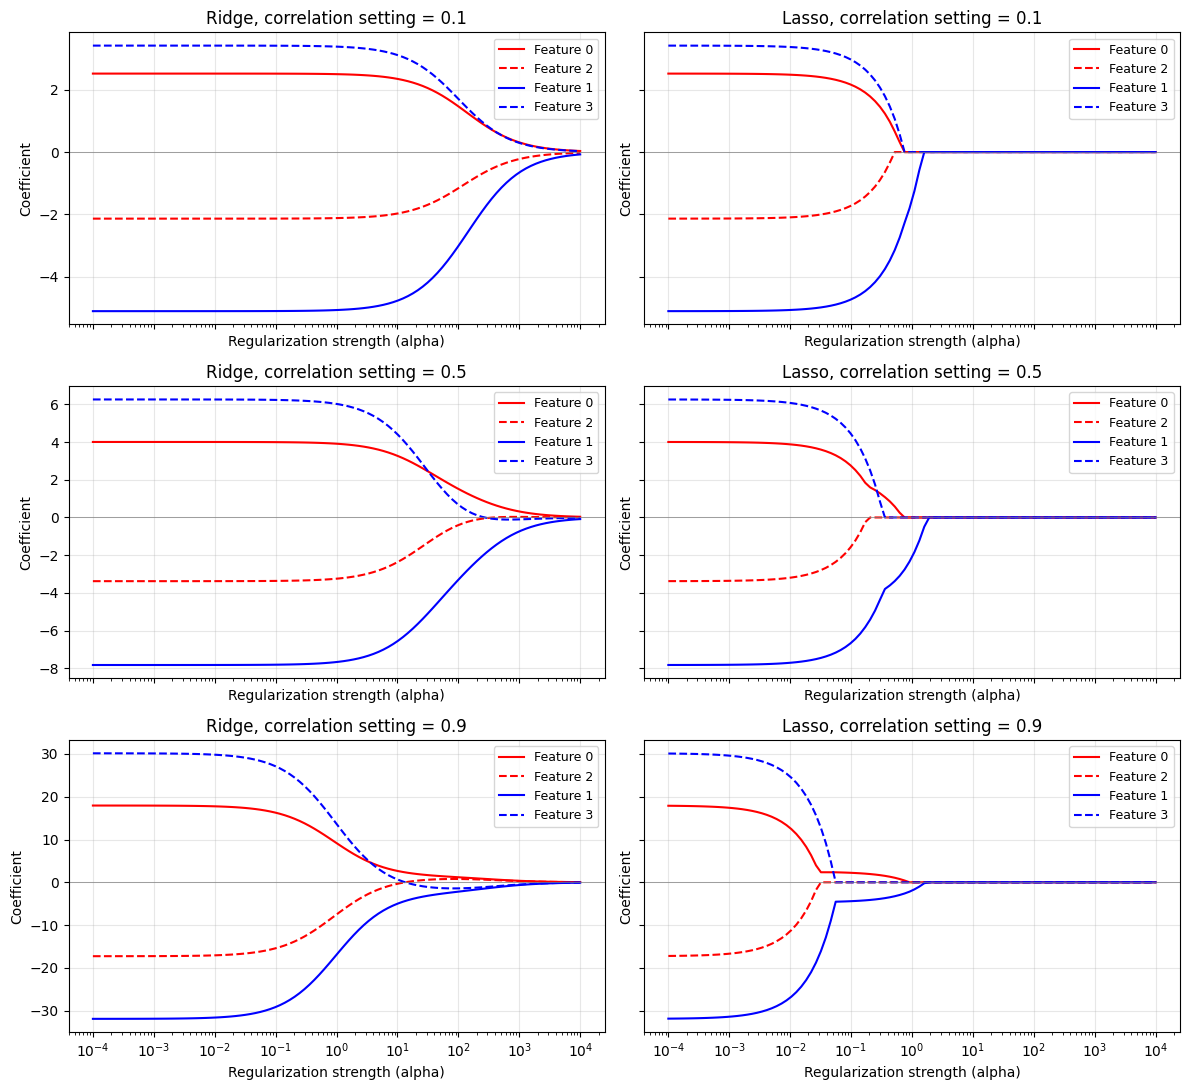

In [ ]:
from tqdm import tqdm

fig, axes = plt.subplots(3, 2, figsize=(12, 11), sharex=True, sharey='row')
row = 0

for correlation in [0.1, 0.5, 0.9]:
  # dataset to fit (no need to split into train/test in this task):
  X, y = gen_data(500, correlation)

  # regularization powers:
  alpha_values = np.logspace(-4, 4, 100, base=10)

  # lists to collect models' parameters:
  params_ridge = []
  params_lasso = []

  for alpha in tqdm(alpha_values):
    ridge = Ridge(alpha=alpha, fit_intercept=False)
    # Allowed extra iterations for strongly correlated features.
    lasso = Lasso(alpha=alpha, fit_intercept=False, max_iter=10000)

    ridge.fit(X, y)
    lasso.fit(X, y)
    params_ridge.append(ridge.coef_)
    params_lasso.append(lasso.coef_)

  params_ridge = np.array(params_ridge)
  params_lasso = np.array(params_lasso)

  for ax, params, name in zip(axes[row], [params_ridge, params_lasso], ['Ridge', 'Lasso']):
    # Used matching colors for correlated pairs and different line styles.
    ax.plot(alpha_values, params[:, 0], color='red', label='Feature 0')
    ax.plot(alpha_values, params[:, 2], '--', color='red', label='Feature 2')
    ax.plot(alpha_values, params[:, 1], color='blue', label='Feature 1')
    ax.plot(alpha_values, params[:, 3], '--', color='blue', label='Feature 3')
    ax.set_xscale('log')
    ax.set_title(f'{name}, correlation setting = {correlation}')
    ax.set_xlabel('Regularization strength (alpha)')
    ax.set_ylabel('Coefficient')
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

  row += 1

plt.tight_layout()
plt.show()


<!-- #changed -->
**Observations:**

Ridge shrank the coefficients towards zero overall, but did not remove features completely. Lasso set coefficients exactly to zero and, at large alpha, removed all features.

With stronger correlation, the coefficients were larger at small alpha and changed more as regularization increased. Lasso sometimes kept one feature from a correlated pair after the other reached zero.

The generator mixed the features after creating the target, so the coefficients describing the same target also changed with the correlation setting. The same alpha did not mean the same penalty strength for Ridge and Lasso because their loss functions used different scaling.
